In [1]:

%pip install lifelines
from lifelines import WeibullAFTFitter

# Check lifelines installation
import lifelines

print("Lifelines version:", lifelines.__version__)

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Lifelines version: 0.30.3


In [2]:
# PAVEMENT TIME-TO-EVENT RESEARCH
# Notebook 02: Weibull AFT Model

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lifelines import WeibullAFTFitter
from IPython.display import display

# Load the prepared training and testing datasets
train_df = pd.read_csv("C:/Users/Nkosinathi Mkhwanazi/Downloads/Research 2 EDUVOS/data/pilot_train_data.csv")
test_df = pd.read_csv("C:/Users/Nkosinathi Mkhwanazi/Downloads/Research 2 EDUVOS/data/pilot_test_data.csv")

# dataset information
print("Training Dataset:", train_df.shape)
print("Testing Dataset:", test_df.shape)

print("\nTraining Events:")
print(train_df["Event"].value_counts())

print("\nTesting Events:")
print(test_df["Event"].value_counts())

display(train_df.head())


Training Dataset: (1618, 17)
Testing Dataset: (399, 17)

Training Events:
Event
0    1435
1     183
Name: count, dtype: int64

Testing Events:
Event
0    360
1     39
Name: count, dtype: int64


,Site_ID,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,PAVEMENT_FAMILY,Start_Date,IRI_Baseline_Value,Rutting_Baseline_Value,IRI_Gap_Days,Rutting_Gap_Days,Lower_Years,Upper_Years,Event,Trigger_Type,Review_Required,IRI_Baseline_Review,Rutting_Baseline_Review
0,01-0102,1,0102,1,ACUB,1994-08-25,0.941,5.0,0,140,6.532512,6.995209,1,Rutting,False,False,False
1,01-0103,1,0103,1,ACTB,1996-01-10,0.794,4.0,0,0,9.297741,inf,0,Censored,False,False,False
2,01-0104,1,0104,1,ACTB,1996-01-10,0.593,5.0,0,0,9.297741,inf,0,Censored,False,False,False
3,01-0105,1,0105,1,ACTB,1996-01-10,0.609,6.0,0,0,5.618070,6.012320,1,Rutting,False,False,False
4,01-0106,1,0106,1,ACTB,1994-08-25,0.737,6.0,0,140,10.674880,inf,0,Censored,False,False,False


In [3]:
# 2. FIT THE FIRST WEIBULL AFT MODEL
# Select baseline predictors
predictors = [
    "IRI_Baseline_Value",
    "Rutting_Baseline_Value"
]

# Prepare training variables
weibull_train = train_df[
    ["Lower_Years", "Upper_Years"] + predictors
].copy()

# Create the Weibull AFT model
weibull_model = WeibullAFTFitter()

# Fit the model using interval-censored data
weibull_model.fit_interval_censoring(
    weibull_train,
    lower_bound_col="Lower_Years",
    upper_bound_col="Upper_Years"
)

#  results
print("WEIBULL AFT MODEL RESULTS")

weibull_model.print_summary()

display(weibull_model.summary)


WEIBULL AFT MODEL RESULTS


<lifelines.WeibullAFTFitter: fitted with 1618 total observations, 1618 interval-censored observations>
          lower bound col = 'Lower_Years'
          upper bound col = 'Upper_Years'
                event col = 'E_lifelines_added'
   number of observations = 1618
number of events observed = 0
           log-likelihood = -799.83
         time fit was run = 2026-11-23 15:31:19 UTC

---
                                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param   covariate                                                                                                               
lambda_ IRI_Baseline_Value     -0.20      0.82      0.16           -0.51            0.11                0.60                1.12
        Rutting_Baseline_Value -0.42      0.66      0.04           -0.50           -0.33                0.60                0.72
        Intercept               6.12    456.49      0.34            5.45            6.80              233.16              893.77
rho_    Intercept              -0.06      0.94      0.07           -0.19            0.07                0.82                1.08

                                cmp to     z      p  -log2(p)
param   covariate                                            
lambda_ IRI_Baseline_Value        0.00 -1.25   0.21      2.24
        Rutting_Baseline_Value    0.00 -9.29 <0.005     65.81
        Intercept                 0.00 17.86 <0.005    234.67
rho_    Intercept                 0.00 -0.86   0.39      1.37
---
AIC = 1607.67
log-likelihood ratio test = 137.81 on 2 df
-log2(p) of ll-ratio test = 99.41

coef   exp(coef)  se(coef)  \
param   covariate                                                
lambda_ IRI_Baseline_Value     -0.199450    0.819181  0.159766   
        Rutting_Baseline_Value -0.415030    0.660320  0.044676   
        Intercept               6.123578  456.494975  0.342799   
rho_    Intercept              -0.059043    0.942667  0.068367   

                                coef lower 95%  coef upper 95%  \
param   covariate                                                
lambda_ IRI_Baseline_Value           -0.512585        0.113685   
        Rutting_Baseline_Value       -0.502593       -0.327468   
        Intercept                     5.451704        6.795451   
rho_    Intercept                    -0.193039        0.074954   

                                exp(coef) lower 95%  exp(coef) upper 95%  \
param   covariate                                                          
lambda_ IRI_Baseline_Value                 0.598945             1.120399   
        Rutting_Baseline_Value             0.604960             0.720747   
        Intercept                        233.155119           893.772622   
rho_    Intercept                          0.824450             1.077834   

                                cmp to          z             p    -log2(p)  
param   covariate                                                            
lambda_ IRI_Baseline_Value         0.0  -1.248389  2.118886e-01    2.238622  
        Rutting_Baseline_Value     0.0  -9.289870  1.544770e-20   65.811170  
        Intercept                  0.0  17.863464  2.270986e-71  234.673576  
rho_    Intercept                  0.0  -0.863615  3.877993e-01    1.366618

In [4]:
# 3. VERIFY EVENT AND CENSORING INFORMATION

# Identify interval-censored maintenance events
interval_events = (
    np.isfinite(train_df["Upper_Years"]) &
    (train_df["Upper_Years"] > train_df["Lower_Years"])
)

# Identify right-censored observations
right_censored = np.isinf(train_df["Upper_Years"])

print("WEIBULL CENSORING SUMMARY")

print("Total observations:", len(train_df))
print("Interval-censored events:", interval_events.sum())
print("Right-censored observations:", right_censored.sum())

# Check agreement with original event indicator
event_match = (
    train_df["Event"] == interval_events.astype(int)
).all()

print("Event classification consistent:", event_match)

WEIBULL CENSORING SUMMARY
Total observations: 1618
Interval-censored events: 183
Right-censored observations: 1435
Event classification consistent: True


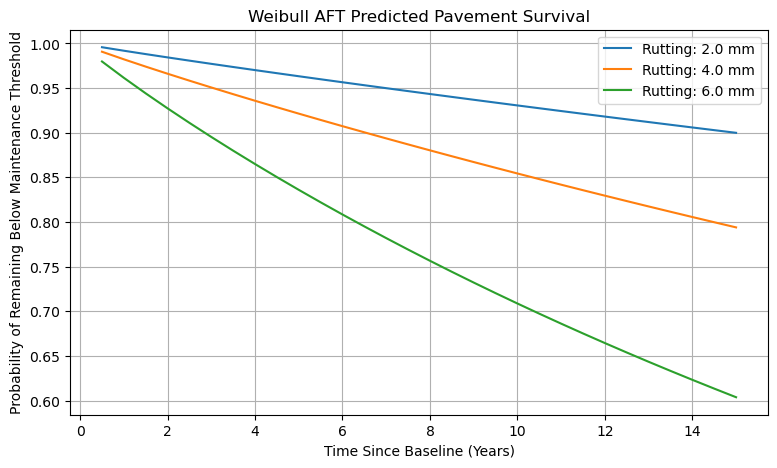

In [5]:
# 4. PLOT WEIBULL SURVIVAL PREDICTIONS

# Create representative pavement conditions
profiles = pd.DataFrame({
    "IRI_Baseline_Value": [
        train_df["IRI_Baseline_Value"].median()
    ] * 3,
    "Rutting_Baseline_Value": [
        train_df["Rutting_Baseline_Value"].quantile(0.25),
        train_df["Rutting_Baseline_Value"].median(),
        train_df["Rutting_Baseline_Value"].quantile(0.75)
    ]
})

# Predict survival probabilities over 15 years
time_points = np.arange(0.5, 15.5, 0.5)

survival_predictions = weibull_model.predict_survival_function(
    profiles,
    times=time_points
)

#  survival curves
plt.figure(figsize=(9, 5))

for i in range(len(profiles)):
    plt.plot(
        survival_predictions.index,
        survival_predictions.iloc[:, i],
        label=f"Rutting: {profiles.iloc[i]['Rutting_Baseline_Value']:.1f} mm"
    )

plt.title("Weibull AFT Predicted Pavement Survival")
plt.xlabel("Time Since Baseline (Years)")
plt.ylabel("Probability of Remaining Below Maintenance Threshold")
plt.legend()
plt.grid(True)
plt.show()


In [6]:
# 5. EVALUATE WEIBULL MODEL USING TEST DATA

# Prepare the testing dataset
weibull_test = test_df[
    ["Lower_Years", "Upper_Years", "Event"] + predictors
].copy().reset_index(drop=True)

# Extract event and censoring information
lower = weibull_test["Lower_Years"].to_numpy()
upper = weibull_test["Upper_Years"].to_numpy()
event = weibull_test["Event"].to_numpy().astype(bool)

# Identify the times needed for evaluation
time_points = np.unique(
    np.concatenate([lower, upper[event]])
)

# Predict survival probabilities for testing observations
test_survival = weibull_model.predict_survival_function(
    weibull_test[predictors],
    times=time_points
).to_numpy()

# Calculate survival probability at each lower bound
row_index = np.searchsorted(time_points, lower)
column_index = np.arange(len(weibull_test))

survival_lower = test_survival[
    row_index, column_index
]

# Calculating the probability assigned to each observation
probability = survival_lower.copy()

event_columns = column_index[event]
event_rows = np.searchsorted(
    time_points, upper[event]
)

# For events: probability of crossing within the interval
probability[event] = (
    survival_lower[event] -
    test_survival[event_rows, event_columns]
)

# Calculate negative log-likelihood
probability = np.clip(probability, 1e-12, 1.0)

test_nll = -np.log(probability).mean()

print("WEIBULL AFT TEST RESULTS")
print("Testing observations:", len(weibull_test))
print("Interval-censored events:", event.sum())
print("Right-censored observations:", (~event).sum())
print("Average negative log-likelihood:", round(test_nll, 4))


WEIBULL AFT TEST RESULTS
Testing observations: 399
Interval-censored events: 39
Right-censored observations: 360
Average negative log-likelihood: 0.4255


In [7]:
# 6. EVALUATE EVENT AND CENSORING LIKELIHOOD
# Calculate negative log-likelihood for each observation
individual_nll = -np.log(probability)

# Calculate average losses for each group
event_nll = individual_nll[event].mean()
censored_nll = individual_nll[~event].mean()

print("WEIBULL AFT PERFORMANCE SUMMARY")

print("Overall NLL:", round(test_nll, 4))
print("Event NLL:", round(event_nll, 4))
print("Right-Censored NLL:", round(censored_nll, 4))

# Create results summary
performance_summary = pd.DataFrame({
    "Observation Type": [
        "Interval-Censored Events",
        "Right-Censored",
        "Overall"
    ],
    "Observations": [
        event.sum(),
        (~event).sum(),
        len(weibull_test)
    ],
    "Average NLL": [
        event_nll,
        censored_nll,
        test_nll
    ]
})

display(performance_summary)


WEIBULL AFT PERFORMANCE SUMMARY
Overall NLL: 0.4255
Event NLL: 3.331
Right-Censored NLL: 0.1107


,Observation Type,Observations,Average NLL
0,Interval-Censored Events,39,3.331004
1,Right-Censored,360,0.110705
2,Overall,399,0.425471


In [8]:
# 7. COMPARE WEIBULL MODEL WITH REFERENCE MODEL
from lifelines import WeibullFitter

# Fit the reference Weibull model using training data
reference_model = WeibullFitter()

reference_model.fit_interval_censoring(
    lower_bound=train_df["Lower_Years"],
    upper_bound=train_df["Upper_Years"]
)

# Calculate reference survival probabilities on test data
reference_lower = np.exp(
    -((lower / reference_model.lambda_) ** reference_model.rho_)
)

reference_upper = np.exp(
    -((upper[event] / reference_model.lambda_) ** reference_model.rho_)
)

# Calculate observation probabilities
reference_probability = reference_lower.copy()

reference_probability[event] = (
    reference_lower[event] - reference_upper
)

# Calculate the reference negative log-likelihood
reference_probability = np.clip(
    reference_probability, 1e-12, 1.0
)

reference_nll = -np.log(reference_probability).mean()

# Compare both models
print("WEIBULL MODEL COMPARISON")

print("Reference Weibull NLL:", round(reference_nll, 4))
print("Weibull AFT NLL:", round(test_nll, 4))

print(
    "NLL Improvement:",
    round(reference_nll - test_nll, 4)
)

# Display comparison table
comparison = pd.DataFrame({
    "Model": [
        "Reference Weibull",
        "Weibull AFT"
    ],
    "Test NLL": [
        reference_nll,
        test_nll
    ]
})

display(comparison)


WEIBULL MODEL COMPARISON
Reference Weibull NLL: 0.4627
Weibull AFT NLL: 0.4255
NLL Improvement: 0.0373


,Model,Test NLL
0,Reference Weibull,0.462729
1,Weibull AFT,0.425471


In [9]:
# 8. COMPARE EVENT AND CENSORING PERFORMANCE

# Calculate individual negative log-likelihoods
aft_losses = -np.log(probability)
reference_losses = -np.log(reference_probability)

# Create comparison table
comparison_details = pd.DataFrame({
    "Observation Type": [
        "Interval-Censored Events",
        "Right-Censored",
        "Overall"
    ],
    "Reference Weibull": [
        reference_losses[event].mean(),
        reference_losses[~event].mean(),
        reference_losses.mean()
    ],
    "Weibull AFT": [
        aft_losses[event].mean(),
        aft_losses[~event].mean(),
        aft_losses.mean()
    ]
})

# Calculate improvement
comparison_details["NLL Improvement"] = (
    comparison_details["Reference Weibull"] -
    comparison_details["Weibull AFT"]
)

print("DETAILED WEIBULL PERFORMANCE COMPARISON")

display(comparison_details.round(4))


DETAILED WEIBULL PERFORMANCE COMPARISON


,Observation Type,Reference Weibull,Weibull AFT,NLL Improvement
0,Interval-Censored Events,3.6742,3.3310,0.3432
1,Right-Censored,0.1148,0.1107,0.0041
2,Overall,0.4627,0.4255,0.0373


WEIBULL MODEL IMPROVEMENT VALIDATION
Observed NLL Improvement: 0.0373
95% Bootstrap Confidence Interval: 0.0106 to 0.0651
Bootstrap Samples: 1000


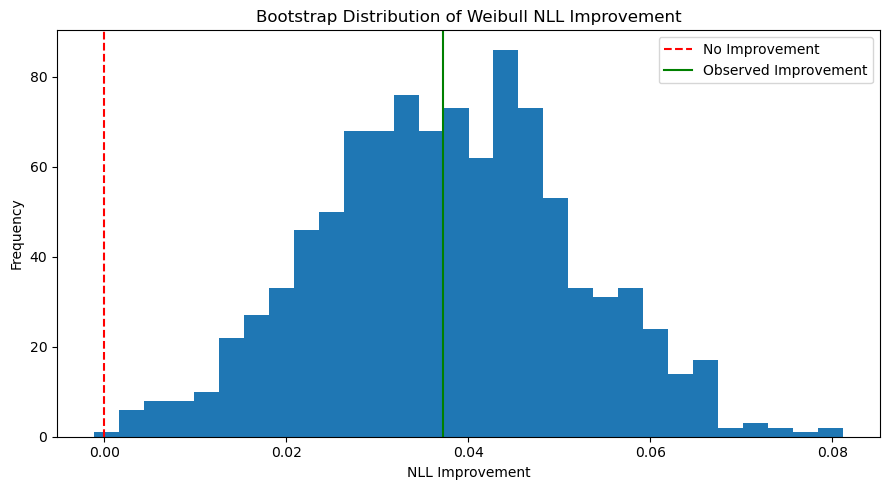

In [10]:
# 9. ASSESS WEIBULL MODEL IMPROVEMENT USING BOOTSTRAPPING

# Calculate the improvement for each observation
test_results = test_df[["Site_ID"]].copy().reset_index(drop=True)

test_results["NLL_Improvement"] = (
    reference_losses - aft_losses
)

# Group the observations by physical pavement section
site_groups = {
    site: group["NLL_Improvement"].to_numpy()
    for site, group in test_results.groupby("Site_ID")
}

# Set the random seed
np.random.seed(42)

# Bootstrap sampling
bootstrap_results = []

site_ids = list(site_groups.keys())

for i in range(1000):

    # Randomly sample pavement sections with replacement
    sampled_sites = np.random.choice(
        site_ids,
        size=len(site_ids),
        replace=True
    )

    # Include all construction periods from each sampled section
    sampled_improvements = np.concatenate([
        site_groups[site] for site in sampled_sites
    ])

    # Calculate the average improvement
    bootstrap_results.append(
        sampled_improvements.mean()
    )

# Calculating the 95% confidence interval
lower_ci = np.percentile(bootstrap_results, 2.5)
upper_ci = np.percentile(bootstrap_results, 97.5)

print("WEIBULL MODEL IMPROVEMENT VALIDATION")

print("Observed NLL Improvement:",
      round(reference_nll - test_nll, 4))

print("95% Bootstrap Confidence Interval:",
      round(lower_ci, 4), "to", round(upper_ci, 4))

print("Bootstrap Samples:", len(bootstrap_results))

#  bootstrap results
plt.figure(figsize=(9, 5))

plt.hist(bootstrap_results, bins=30)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="No Improvement"
)

plt.axvline(
    reference_nll - test_nll,
    color="green",
    linestyle="-",
    label="Observed Improvement"
)

plt.title("Bootstrap Distribution of Weibull NLL Improvement")
plt.xlabel("NLL Improvement")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()


In [11]:

# 10. SAVE WEIBULL MODEL RESULTS

from pathlib import Path

# Create a folder for model results
results_folder = Path("results")
results_folder.mkdir(exist_ok=True)

# Save the Weibull model coefficients
weibull_model.summary.to_csv(
    results_folder / "weibull_aft_coefficients.csv"
)

# Save the model comparison
comparison_details.to_csv(
    results_folder / "weibull_model_comparison.csv",
    index=False
)

# Save the bootstrap results
bootstrap_summary = pd.DataFrame({
    "Model": ["Weibull AFT"],
    "Reference_NLL": [reference_nll],
    "Weibull_AFT_NLL": [test_nll],
    "NLL_Improvement": [reference_nll - test_nll],
    "Bootstrap_Lower_95": [lower_ci],
    "Bootstrap_Upper_95": [upper_ci],
    "Training_Observations": [len(train_df)],
    "Testing_Observations": [len(test_df)],
    "Testing_Events": [event.sum()]
})

bootstrap_summary.to_csv(
    results_folder / "weibull_bootstrap_summary.csv",
    index=False
)

print("WEIBULL RESULTS SAVED SUCCESSFULLY")
print("Folder:", results_folder.resolve())

display(bootstrap_summary.round(4))


WEIBULL RESULTS SAVED SUCCESSFULLY
Folder: C:\Users\Nkosinathi Mkhwanazi\Downloads\Research 2 EDUVOS\results


,Model,Reference_NLL,Weibull_AFT_NLL,NLL_Improvement,Bootstrap_Lower_95,Bootstrap_Upper_95,Training_Observations,Testing_Observations,Testing_Events
0,Weibull AFT,0.4627,0.4255,0.0373,0.0106,0.0651,1618,399,39
